## Mini Batch

In [2]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

from utils import SIZE, CLASSES, prepare_data_set, plot_costs, load_image, get_label
from checks import check_l2_cost
from dnn import (
    relu, sigmoid, initialize_parameters, activate,
    ActivationCache, PropagateCache, ForwardCache,
    propagate, propagate_backward,
    AL_derivative, relu_backward, sigmoid_backward,
)

In [3]:
datasets = prepare_data_set()

Y_train = datasets["Y_train"]
X_train = datasets ["X_train"]
X_test = datasets["X_test"]
Y_test = datasets["Y_test"]
X_test_orig_set = datasets["X_test_orig_set"]
X_train_orig_set = datasets["X_train_orig_set"]


In [4]:
def forward_pass(X, parameters):
    # find the number of layers from the initialized parameters
    L = len(parameters) // 2

    # print(f"Len Layer: {L}")
    cache = [] # we need this later for backward propagation
    Aprev = X # initial assignment to A0
    for l in range(0,L):
        # here we calculate Zl     
        Zl, pc = propagate(parameters["W"+str(l+1)], Aprev, parameters["b"+str(l+1)])
        # here we calculate Al (it should be started from 1 by the loop)
        if (l == (L-1)): # for output layer, we use sigmoid
            Aprev, ac= activate(Zl, "sigmoid")
        else:
            Aprev, ac= activate(Zl, "relu")
        forward_cache = ForwardCache(PropagateCache = pc, ActivationCache=ac) 
        cache.append(forward_cache)
    output = Aprev
    # print(f"Len in forward: {len(cache)} {len(parameters)} ")
    return output, cache

In [46]:
def backward_pass(AL, Y, caches):

    grads = {}
    L = len(caches)
    current_layer_cache = caches[L-1]
    current_layer_W = current_layer_cache.PropagateCache.W
    current_layer_Aprev = current_layer_cache.PropagateCache.Aprev
    
    # get the dZ for outer/output layer
    # sigmoid + binary cross-entropy simplifies to dZ = AL - Y
    dZ = AL-Y
    dW,db, dAprev = propagate_backward(dZ, current_layer_Aprev, current_layer_W )
    grads["dW"+str(L)] = dW
    grads["db"+str(L)] = db

    # print(f"l in backward = {L}")
    
    for l in reversed (range (L-1)):
        current_layer_cache = caches[l]
        current_layer_W = current_layer_cache.PropagateCache.W
        current_layer_Aprev = current_layer_cache.PropagateCache.Aprev
        dZ = relu_backward(dAprev, current_layer_cache.ActivationCache)
        dW,db,dAprev = propagate_backward(dZ, current_layer_Aprev, current_layer_W)
        # print(f"l in backward = {l+1}")
        grads["dW" + str(l+1)] = dW
        grads["db" + str(l+1)] = db
    
    return grads


def backward_pass_L2(AL, Y, caches, lambd, m):
    grads = backward_pass(AL,Y, caches)
    L = len(caches)
    for l in reversed (range (0, L)):
        cc = caches[l].PropagateCache
        grads["dW"+str(l+1)] = grads["dW"+str(l+1)] + ((lambd / m) * cc.W)
        
    return grads

In [45]:
def calculate_cost(AL,Y):
    m = AL.shape[1]
    # clip AL to avoid log(0).
    AL = np.clip(AL, 1e-8, 1 - 1e-8)
    cost =  -(1./m) * np.sum((np.dot(Y,np.log(AL).T) + np.dot(1-Y, np.log(1-AL).T)))
    # make sure the output not a 0-dimensional array/scalar
    # eg 2D array (matrix) number: [[24]] => become 24.
    res = np.squeeze(cost)
    return res

def calculate_cost_L2(AL,Y, parameters, lambd, m):
    cost = calculate_cost(AL,Y)
    L = len(parameters)//2
    Wl = []
    for l in range(1,L+1):
        W = np.sum(np.square(parameters["W"+str(l)]))
        Wl.append(W)

    L2_regularization_cost = (lambd / (2 * m)) * np.sum(Wl)
    cost = cost + L2_regularization_cost
    return cost


    

In [7]:
def update_parameter(parameters, grads, learning_rate):

    # floor divide by 2 because each layer has both a 'W' and a 'b'
    L = len(parameters) // 2
    
    for l in range (0, L):
        parameters["W" + str(l+1)] = parameters["W" + str(l+1)] - (learning_rate * grads["dW"+str(l+1)])
        parameters["b" + str(l+1)] = parameters["b" + str(l+1)] - (learning_rate * grads["db"+str(l+1)])

    assert len(grads) == len(parameters)
    return parameters


In [8]:
# classify will apply the propagation with the given parameters
# and return the classification as 1 or 0
def classify(X,parameters):
    output, _ = forward_pass(X,parameters)
    return (output > 0.5).astype(int)


def random_mini_batches(X, Y, mini_batch_size=64, seed=3):
    np.random.seed(seed)
    m = X.shape[1]
    total_batches =  m // mini_batch_size

    permutation = list(np.random.permutation(m))
    shuffled_X = X[:, permutation]
    shuffled_Y = Y[:, permutation].reshape((1,m))
    
    mini_batches = []
    for k in range (0, total_batches):
        i = k * mini_batch_size
        j = (k+1) * mini_batch_size
        mini_X = shuffled_X[:, i:j]
        mini_Y = shuffled_Y[:, i:j]
        mini_batch = (mini_X, mini_Y)
        mini_batches.append(mini_batch)
    if m % mini_batch_size != 0:
        i = total_batches * mini_batch_size
        mini_X = shuffled_X[:, i:]
        mini_Y = shuffled_Y[:, i:]
        mini_batch = (mini_X, mini_Y)
        mini_batches.append(mini_batch)


    return mini_batches


In [9]:
def initialize_velocity(parameters):
    L = len(parameters)//2
    v = {}

    for l in range (1, L+1):
        W = parameters["W" + str(l)]
        b = parameters ["b"+ str(l)]

        v["dW" + str(l)] = np.zeros(W.shape)
        v["db" + str(l)] = np.zeros(b.shape)

    return v

def update_parameter_with_momentum(parameters, grads, v,beta, learning_rate):

    L = len(parameters)//2

    for l in range (1, L+1):
        v["dW"+str(l)] = beta * v["dW"+str(l)] + (1 - beta) * grads["dW"+str(l)]
        v["db"+str(l)] = beta * v["db"+str(l)] + (1 - beta) * grads["db"+str(l)]

        parameters["W"+str(l)] = parameters["W"+str(l)] - learning_rate * v["dW"+str(l)]
        parameters["b"+str(l)] = parameters["b"+str(l)] - learning_rate * v["db"+str(l)]

    return parameters, v


In [10]:

def initialize_squared_prop(parameters):
    L = len(parameters)//2
    s = {}

    for l in range (1, L+1):
        W = parameters["W" + str(l)]
        b = parameters ["b"+ str(l)]

        s["dW" + str(l)] = np.zeros(W.shape)
        s["db" + str(l)] = np.zeros(b.shape)

    return s

def update_parameter_with_rmsprop(parameters, grads, s,beta, epsilon, learning_rate):

    L = len(parameters)//2

    for l in range (1, L+1):
        s["dW"+str(l)] = beta * s["dW"+str(l)] + (1 - beta) * np.power(grads["dW"+str(l)],2)
        s["db"+str(l)] = beta * s["db"+str(l)] + (1 - beta) * np.power(grads["db"+str(l)],2)

        parameters["W"+str(l)] = parameters["W"+str(l)] - learning_rate * (grads["dW"+str(l)] /  (np.sqrt(s["dW"+str(l)]) + epsilon))
        parameters["b"+str(l)] = parameters["b"+str(l)] - learning_rate * (grads["db"+str(l)] /  (np.sqrt(s["db"+str(l)]) + epsilon))

    return parameters, s


In [11]:

def initialize_adam(parameters):
    L = len(parameters)//2
    s = {}
    v = {}

    for l in range (1, L+1):
        W = parameters["W" + str(l)]
        b = parameters ["b"+ str(l)]

        s["dW" + str(l)] = np.zeros(W.shape)
        s["db" + str(l)] = np.zeros(b.shape)
        v["dW" + str(l)] = np.zeros(W.shape)
        v["db" + str(l)] = np.zeros(b.shape)

    return s,v

def update_parameter_with_adam(parameters, grads, s, v, beta1, beta2, epsilon, t, learning_rate):

    L = len(parameters)//2
    s_corrected = {}
    v_corrected = {}
    for l in range (1, L+1):
        v["dW"+str(l)] = beta1 * v["dW"+str(l)] + (1 - beta1) * grads["dW"+str(l)]
        v["db"+str(l)] = beta1 * v["db"+str(l)] + (1 - beta1) * grads["db"+str(l)]
        
        s["dW"+str(l)] = beta2 * s["dW"+str(l)] + (1 - beta2) * np.power(grads["dW"+str(l)],2)
        s["db"+str(l)] = beta2 * s["db"+str(l)] + (1 - beta2) * np.power(grads["db"+str(l)],2)
        

        v_corrected["dW"+str(l)] = v["dW"+str(l)] / (1 - np.power(beta1,t))
        v_corrected["db"+str(l)] = v["db"+str(l)] / (1 - np.power(beta1,t))
        
        s_corrected["dW"+str(l)] = s["dW"+str(l)] / (1 - np.power(beta2, t))
        s_corrected["db"+str(l)] = s["db"+str(l)] / (1 - np.power(beta2, t))

        parameters["W"+str(l)] = parameters["W"+str(l)] - learning_rate * (v_corrected["dW"+str(l)] /  (np.sqrt(s_corrected["dW"+str(l)]) + epsilon))
        parameters["b"+str(l)] = parameters["b"+str(l)] - learning_rate * (v_corrected["db"+str(l)] /  (np.sqrt(s_corrected["db"+str(l)]) + epsilon))

    return parameters, s, v, s_corrected, v_corrected


In [47]:
# optimizer: "plain", "momentum", "rmsprop" or "adam"
# beta is used by momentum and rmsprop, beta1/beta2 by adam, epsilon by rmsprop and adam
def dnn_model_mini_batch(X_train, Y_train, X_test, Y_test, layers_dims, iteration=2500, 
              learning_rate=0.0075, mini_batch_size=64, seed = 3, optimizer="plain",
              beta=0.9, beta1=0.9, beta2=0.999, epsilon=1e-8, lambd=0.01, print_cost=False):
    
    parameters = initialize_parameters(layers_dims)
    match optimizer:
        case "plain":
            pass
        case "momentum":
            v = initialize_velocity(parameters)
        case "rmsprop":
            s = initialize_squared_prop(parameters)
        case "adam":
            s,v = initialize_adam(parameters)
        case _:
            raise ValueError(f"unknown optimizer {optimizer!r}, use plain, momentum, rmsprop or adam")

    epoch_costs = []
    batch_costs = []
    t = 0
    m_total = X_train.shape[1]
    for i in range(1,iteration+1):
        mini_batches = random_mini_batches(X_train, Y_train, mini_batch_size, seed+i)
        num_batches = len(mini_batches)
        this_epoch_costs = []
        for k in range (0, num_batches):
            X, Y = mini_batches[k]
            AL, cache = forward_pass(X, parameters)
            cost = calculate_cost_L2(AL,Y, parameters, lambd, m_total)
            this_epoch_costs.append(cost)
            batch_costs.append(cost)
            grads = backward_pass_L2(AL, Y, cache, lambd, m_total)
            match optimizer:
                case "plain":
                    parameters = update_parameter(parameters, grads, learning_rate)
                case "momentum":
                    parameters,v = update_parameter_with_momentum(parameters, grads, v, beta, learning_rate)
                case "rmsprop":
                    parameters,s = update_parameter_with_rmsprop(parameters, grads, s, beta, epsilon, learning_rate)
                case "adam":
                    t = t + 1
                    parameters,s,v,_,_ = update_parameter_with_adam(parameters, grads, s,v, beta1, beta2, epsilon, t, learning_rate)
        
        cost_avg = np.average(this_epoch_costs)
        epoch_costs.append(cost_avg)
        if (i%100 == 0) and print_cost:
            print(f"Cost: {cost_avg}")
    
    
    Y_prediction_train = classify(X_train, parameters)
    Y_prediction_test  = classify(X_test, parameters)

    train_acc = 100 - np.mean(np.abs(Y_prediction_train - Y_train)) * 100
    test_acc = 100 - np.mean(np.abs(Y_prediction_test - Y_test)) * 100
    print(f"train_accuracy: {train_acc}%")
    print(f"test_accuracy: {test_acc}%")

    return parameters, batch_costs, epoch_costs

In [61]:
import time
start_time = time.perf_counter()
input_features = X_train.shape[0]
iteration = 900
learning_rate = 0.0001
mini_batch_size = 128
seed = 3
beta1= 0.9
beta2=0.999
epsilon = 1e-8
lambd = 100
layer_dims_deep = [input_features, 30, 20, 10, 1]
parameter_deep, batch_costs, epoch_costs = dnn_model_mini_batch(
        X_train=X_train,
        Y_train=Y_train,
        X_test=X_test,
        Y_test=Y_test,
        layers_dims=layer_dims_deep,
        iteration=iteration,
        learning_rate=learning_rate,
        mini_batch_size=mini_batch_size,
        seed=seed,
        optimizer="adam",
        beta1=beta1,
        beta2=beta2,
        epsilon=epsilon,
        lambd=lambd,
        print_cost=True)

elapsed_minutes = (time.perf_counter() - start_time) / 60
print(f"Execution time: {elapsed_minutes:.2f} minutes")

Cost: 0.6623380282909171
Cost: 0.596390735265088
Cost: 0.565748192376681
Cost: 0.5275709692088303
Cost: 0.48938644854745433
Cost: 0.46868267001386393
Cost: 0.4606534685848345
Cost: 0.41986340655600457
Cost: 0.4077241319617701
train_accuracy: 94.62835727670206%
test_accuracy: 62.58032624814632%
Execution time: 6.91 minutes


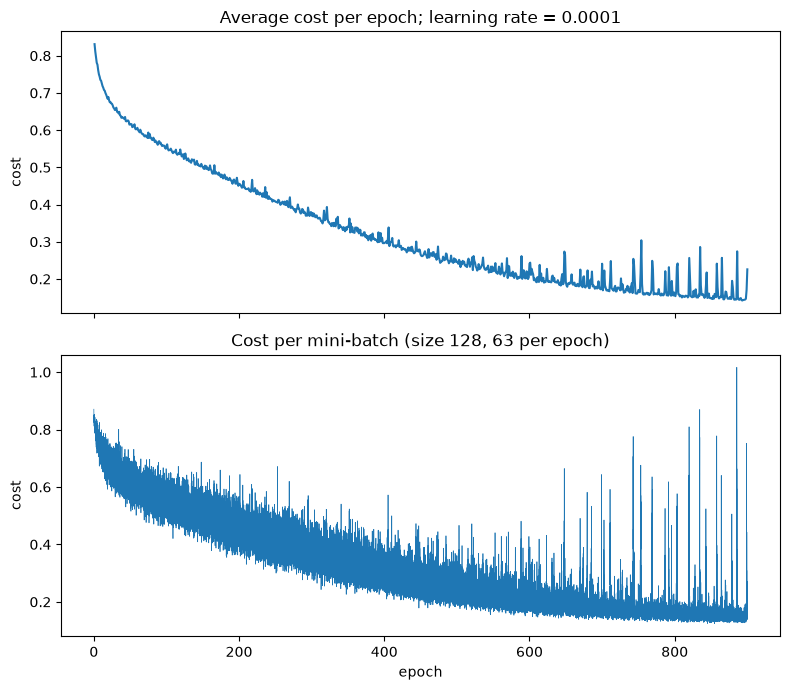

In [54]:
# epoch_costs has one point per epoch, batch_costs one point per mini-batch update.
# Put both on an epoch axis so the noise of each mini-batch lines up with its epoch.
batches_per_epoch = len(batch_costs) // len(epoch_costs)
epochs = np.arange(1, len(epoch_costs) + 1)
batch_steps = np.arange(1, len(batch_costs) + 1) / batches_per_epoch

fig, (ax_epoch, ax_batch) = plt.subplots(2, 1, sharex=True, figsize=(8, 7))

ax_epoch.plot(epochs, epoch_costs)
ax_epoch.set_title(f"Average cost per epoch; learning rate = {learning_rate}")
ax_epoch.set_ylabel("cost")

ax_batch.plot(batch_steps, batch_costs, linewidth=0.5)
ax_batch.set_title(f"Cost per mini-batch (size {mini_batch_size}, {batches_per_epoch} per epoch)")
ax_batch.set_xlabel("epoch")
ax_batch.set_ylabel("cost")

plt.tight_layout()
plt.show()

In [59]:
for lambd in (40, 60):
      print(f"--- lambd = {lambd}")
      parameter_deep, batch_costs, epoch_costs = dnn_model_mini_batch(
              X_train=X_train,
              Y_train=Y_train,
              X_test=X_test,
              Y_test=Y_test,
              layers_dims=layer_dims_deep,
              iteration=200,
              learning_rate=0.001,
              mini_batch_size=128,
              seed=3,
              optimizer="adam",
              lambd=lambd)
      print("sum W^2:", sum(np.sum(parameter_deep["W"+str(l)]**2) for l in range(1, 5)))

--- lambd = 40
train_accuracy: 70.08119925046846%
test_accuracy: 62.28373702422145%
sum W^2: 14.81952543784469
--- lambd = 60
train_accuracy: 66.68332292317302%
test_accuracy: 60.85022244191794%
sum W^2: 8.553259203110057


In [52]:
import time
start_time = time.perf_counter()
input_features = X_train.shape[0]
iteration = 900
learning_rate = 0.0075
mini_batch_size = 128
seed = 3
beta= 0.9

layer_dims_deep = [input_features, 30, 20, 10, 1]
parameter_deep, batch_costs, epoch_costs = dnn_model_mini_batch(
        X_train=X_train,
        Y_train=Y_train,
        X_test=X_test,
        Y_test=Y_test,
        layers_dims=layer_dims_deep,
        iteration=iteration,
        learning_rate=learning_rate,
        mini_batch_size=mini_batch_size,
        seed=seed,
        optimizer="momentum",
        beta=beta,
        print_cost=True)

elapsed_minutes = (time.perf_counter() - start_time) / 60
print(f"Execution time: {elapsed_minutes:.2f} minutes")

Cost: 0.3771761625849824
Cost: 0.1455031617258612
Cost: 0.020303223522183833
Cost: 0.0026815781721766943
Cost: 0.0012326126446924725
Cost: 0.0007522432763871065
Cost: 0.0005434615979453324
Cost: 0.0004001342241800376
Cost: 0.0003213950777696609
train_accuracy: 100.0%
test_accuracy: 62.92634700939199%
Execution time: 6.16 minutes


In [13]:
import time
start_time = time.perf_counter()
input_features = X_train.shape[0]
iteration = 900
learning_rate = 0.0001
mini_batch_size = 128
seed = 3
beta= 0.9
epsilon = 1e-8
layer_dims_deep = [input_features, 30, 20, 10, 1]
parameter_deep, batch_costs, epoch_costs = dnn_model_mini_batch(
        X_train=X_train,
        Y_train=Y_train,
        X_test=X_test,
        Y_test=Y_test,
        layers_dims=layer_dims_deep,
        iteration=iteration,
        learning_rate=learning_rate,
        mini_batch_size=mini_batch_size,
        seed=seed,
        optimizer="rmsprop",
        beta=beta,
        epsilon=epsilon,
        print_cost=True)

elapsed_minutes = (time.perf_counter() - start_time) / 60
print(f"Execution time: {elapsed_minutes:.2f} minutes")

Cost: 0.5098095067392192
Cost: 0.41398162319465887
Cost: 0.3383009241147492
Cost: 0.28173113916715814
Cost: 0.22696899863742206
Cost: 0.1704090971245282
Cost: 0.1483657962133358
Cost: 0.11346079442985092
Cost: 0.09474503148325522
train_accuracy: 99.3628981886321%
test_accuracy: 63.71725160652496%
Execution time: 6.65 minutes


In [31]:
import time
start_time = time.perf_counter()
input_features = X_train.shape[0]
iteration = 900
learning_rate = 0.001
mini_batch_size = 128
seed = 3
beta1= 0.9
beta2=0.999
epsilon = 1e-8
layer_dims_deep = [input_features, 30, 20, 10, 1]
parameter_deep, batch_costs, epoch_costs = dnn_model_mini_batch(
        X_train=X_train,
        Y_train=Y_train,
        X_test=X_test,
        Y_test=Y_test,
        layers_dims=layer_dims_deep,
        iteration=iteration,
        learning_rate=learning_rate,
        mini_batch_size=mini_batch_size,
        seed=seed,
        optimizer="plain",
        beta1=beta1,
        beta2=beta2,
        epsilon=epsilon,
        print_cost=True)

elapsed_minutes = (time.perf_counter() - start_time) / 60
print(f"Execution time: {elapsed_minutes:.2f} minutes")

Cost: 0.4854898808807032
Cost: 0.3031545184970825
Cost: 0.18189942285907107
Cost: 0.1346104913195458
Cost: 0.17236162060466867
Cost: 0.1204783645564439
Cost: 0.2529481684706911
Cost: 0.018419849124805276
Cost: 0.01972382613530825
train_accuracy: 99.91255465334166%
test_accuracy: 58.92239248640633%
Execution time: 7.20 minutes


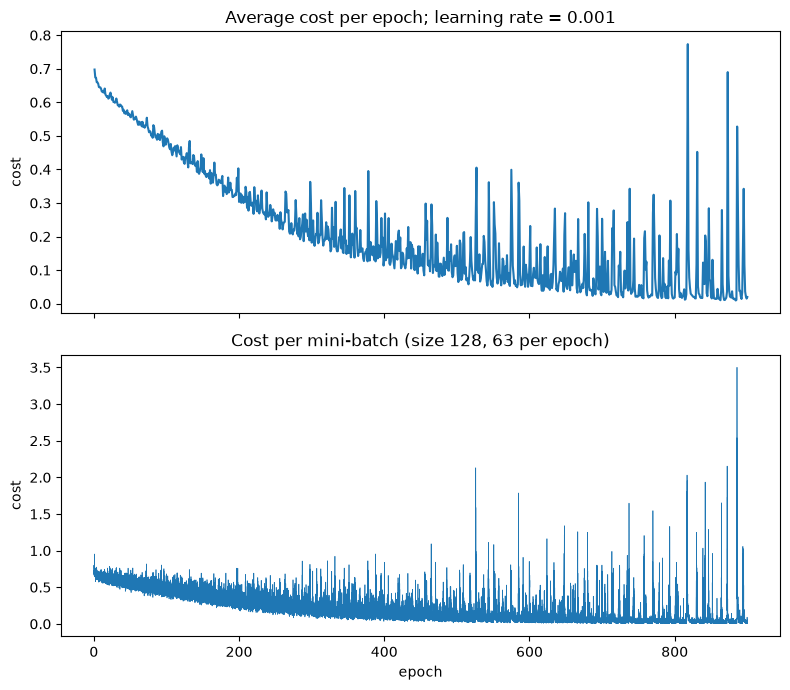

In [32]:
# epoch_costs has one point per epoch, batch_costs one point per mini-batch update.
# Put both on an epoch axis so the noise of each mini-batch lines up with its epoch.
batches_per_epoch = len(batch_costs) // len(epoch_costs)
epochs = np.arange(1, len(epoch_costs) + 1)
batch_steps = np.arange(1, len(batch_costs) + 1) / batches_per_epoch

fig, (ax_epoch, ax_batch) = plt.subplots(2, 1, sharex=True, figsize=(8, 7))

ax_epoch.plot(epochs, epoch_costs)
ax_epoch.set_title(f"Average cost per epoch; learning rate = {learning_rate}")
ax_epoch.set_ylabel("cost")

ax_batch.plot(batch_steps, batch_costs, linewidth=0.5)
ax_batch.set_title(f"Cost per mini-batch (size {mini_batch_size}, {batches_per_epoch} per epoch)")
ax_batch.set_xlabel("epoch")
ax_batch.set_ylabel("cost")

plt.tight_layout()
plt.show()

In [44]:
print(np.round(batch_costs[:20], 3))      # cost of the first 20 updates

AL, cache = forward_pass(X_train, parameter_deep)
print(AL.min(), AL.max())                  # nearly identical values = constant output

[0.721 0.797 2.377 3.37  1.228 2.207 1.952 0.815 1.373 0.731 1.162 0.77
 0.676 0.73  0.692 0.811 0.71  0.766 0.702 0.722]
0.5038267218354932 0.5038267218354932


Deep Neural Network predict it's a cats picture


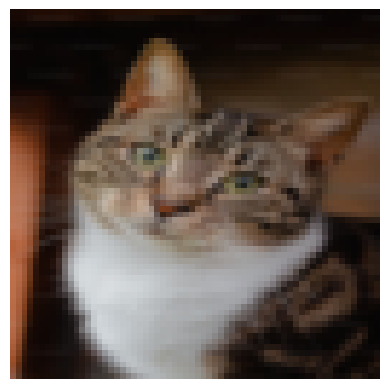

In [20]:
my_image = "cat_focus.png"
image, x_real_data = load_image(my_image)

plt.imshow(image)
plt.axis("off")

# logistic_prediction = classify(x_real_data, parameter_logistic_regression)
# print(f"Logistic Regression predict it's a {get_label(logistic_prediction)} picture")


# shallow_prediction = classify(x_real_data, parameter_shallow)
# print(f"Shallow Neural Network predict it's a {get_label(shallow_prediction)} picture")


deep_prediction = classify(x_real_data, parameter_deep)
print(f"Deep Neural Network predict it's a {get_label(deep_prediction)} picture")